# Project01 Q-learning nhắc nhật ký

Mục tiêu: thực thi một tác tử học chính sách theo phần thưởng, đọc Q-table và so sánh đối chứng. RL chỉ nhắc ghi dữ liệu trong mô phỏng; không kê thuốc, không có outcome lâm sàng.

In [1]:
# Chạy được khi kernel bắt đầu ở PROJECT_01 hoặc notebooks.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "diabetes_agent").exists() else Path.cwd().parent
assert (ROOT / "diabetes_agent").exists(), "Mở notebook từ thư mục PROJECT_01"
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from diabetes_agent.config import ARTIFACTS, DATA, FEATURES
print("Python:", sys.version.split()[0], "| Project:", ROOT.name)

Python: 3.11.9 | Project: PROJECT_01


## 1 Định nghĩa môi trường

Trạng thái $s=2g+f$: số ngày chưa ghi $g\in\{0,1,2,3\}$ (3 nghĩa là từ 3 ngày), mệt vì thông báo $f\in\{0,1\}$. Ba hành động: không nhắc, nhắc nhật ký, gợi ý ghi chép ngắn. Phản ứng ghi nhật ký là Bernoulli với xác suất do tác giả đặt trong `transition`. Reward cộng điểm ghi nhận, trừ chi phí nhắc, ngày thiếu và mệt. Không sử dụng số liệu y khoa để suy ra hệ số này.

Q-learning: $Q(s,a)\leftarrow Q(s,a)+0.08[r+0.92\max_{a'}Q(s',a')-Q(s,a)]$. Đây là bài toán continuing; mỗi rollout cắt ở 28 ngày nhưng vẫn bootstrap ở ngày cuối.

In [2]:
import inspect
from diabetes_agent.rl import transition, train_q, run_experiment, ACTIONS
print(inspect.getsource(transition))
print("Hành động:", ACTIONS)

def transition(state, action, rng):
    gap, fatigue = divmod(int(state), 2)
    # Synthetic response probability; coefficients are author-defined assumptions.
    probability = np.clip(.40 - .07 * gap - .08 * fatigue + [.0, .35, .22][action], .05, .95)
    logged = bool(rng.random() < probability)
    next_gap = 0 if logged else min(3, gap + 1)
    next_fatigue = int(rng.random() < ([.15, .70, .40][action]))
    reward = float(logged) - [.0, .22, .10][action] - .10 * next_gap - .12 * fatigue * (action > 0)
    return 2 * next_gap + next_fatigue, reward, logged

Hành động: ['Không nhắc', 'Nhắc ghi nhật ký', 'Gửi gợi ý ghi chép ngắn']


## 2 Huấn luyện và đánh giá thật
5 seed train 42–46, mỗi seed 1.800 episode. Đánh giá greedy trên 200 seed 10000–10199. Các policy dùng cùng seed để so sánh; Q-table dùng trong demo luôn là seed 42 được quy định trước, không chọn seed tốt nhất.

,mean,std
policy,,
fixed,0.286793,0.000000
never,0.087589,0.000000
q_learning,0.270284,0.015279
rule,0.200589,0.000000


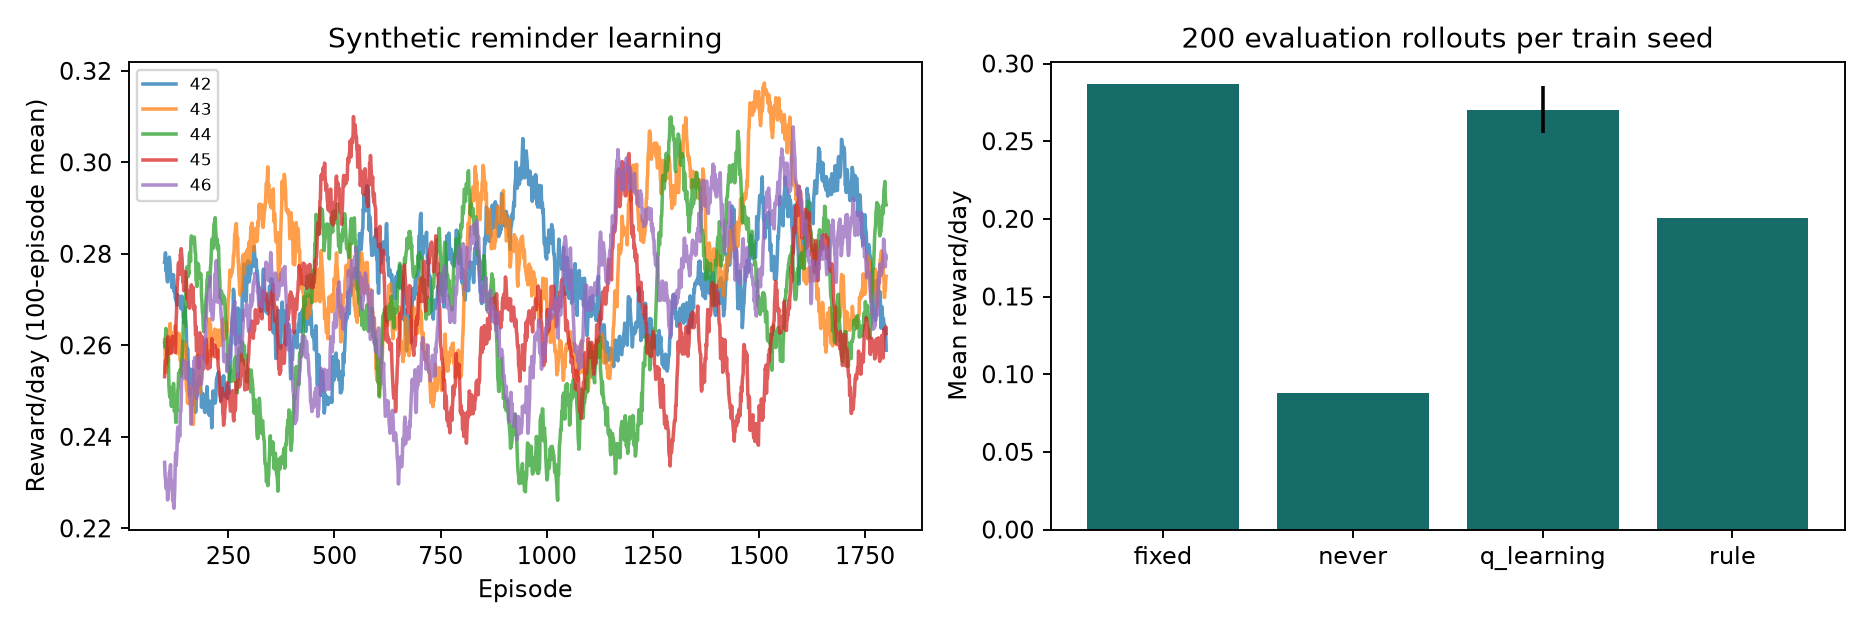

In [3]:
summary = run_experiment()
display(summary)
display(Image(filename=str(ARTIFACTS / "figures/rl.png")))

## 3 Đọc chính sách
Action là argmax của Q cho trạng thái đang xét. Q-value là utility chiết khấu trong simulator, không có đơn vị xác suất hoặc đường huyết.

In [4]:
import numpy as np
q = np.load(ARTIFACTS / "q_table.npy")
policy = pd.DataFrame(q, columns=ACTIONS)
policy.insert(0, "gap_days", np.arange(8)//2)
policy.insert(1, "fatigue", np.arange(8)%2)
policy["chosen_action"] = [ACTIONS[i] for i in q.argmax(axis=1)]
display(policy.round(3))

,gap_days,fatigue,Không nhắc,Nhắc ghi nhật ký,Gửi gợi ý ghi chép ngắn,chosen_action
0,0,0,3.523,3.823,3.516,Nhắc ghi nhật ký
1,0,1,3.638,3.101,3.187,Không nhắc
2,1,0,3.268,3.293,3.465,Gửi gợi ý ghi chép ngắn
3,1,1,3.025,3.077,3.146,Gửi gợi ý ghi chép ngắn
4,2,0,2.977,3.160,3.401,Gửi gợi ý ghi chép ngắn
5,2,1,3.242,2.881,2.925,Không nhắc
6,3,0,2.651,2.962,2.819,Nhắc ghi nhật ký
7,3,1,2.745,2.730,3.060,Gửi gợi ý ghi chép ngắn


## 4 Kiểm tra tính tái lập
Chạy hai lượt seed giống nhau với ít episode để kiểm chứng cơ chế ngẫu nhiên. Đây không thay thế đánh giá hiệu quả trên người thật.

In [5]:
qa, _ = train_q(seed=7, episodes=20)
qb, _ = train_q(seed=7, episodes=20)
assert np.array_equal(qa, qb)
print("PASS: cùng seed tạo cùng Q-table.")
detail = pd.read_csv(ARTIFACTS / "rl_evaluation.csv")
display(detail.groupby("policy")[["reward_per_day", "logging_rate", "reminder_rate"]].mean())

PASS: cùng seed tạo cùng Q-table.


,reward_per_day,logging_rate,reminder_rate
policy,,,
fixed,0.286793,0.649286,1.000000
never,0.087589,0.265000,0.000000
q_learning,0.270284,0.509429,0.743857
rule,0.200589,0.381250,0.265179


**Phân tích:** đọc bảng để kiểm tra Q-learning có vượt policy cố định không. Nếu không vượt, vẫn báo đúng kết quả; không thay reward để tạo ưu thế. Độ lệch chuẩn trong `rl_summary.csv` là giữa năm giá trị trung bình theo seed train; policy cố định có std này bằng 0 vì dùng lại cùng seed eval, không có nghĩa không có biến thiên giữa người dùng mô phỏng.